# Datathon ADW 2026: Diagnóstico Crítico de Impacto Pedagógico & Engajamento — SIA Educação

> **Evento**: AI & Data Week 2026 (ADW) — FEA-RP/USP, Neuron DSAI, Solana Superteam Brasil & SIA Educação  
> **Apresentador**: Pedro Henrique Sandoval (Data Scientist & AI Engineer)  
> **Fundamentação Metodológica**: 
> - **Tamara Munzner** (*Visualization Analysis and Design*, 2014) — Modelo Aninhado de 4 Níveis (*Domain $\rightarrow$ Abstraction $\rightarrow$ Idiom $\rightarrow$ Algorithm*).
> - **Edward Tufte** (*The Visual Display of Quantitative Information*, 1983) — Princípios de Excelência Gráfica, Alta Razão Dado-Tinta (*Data-Ink Ratio*) e Integridade Visual.  
>
> **Alinhamento com o Slide Deck**: Este notebook é a base computacional e estatística que alimenta, célula a célula, a apresentação final em PowerPoint (`Apresentacao_Datathon_SIA_Arena.pptx`).


## Mapeamento: Do Notebook aos Slides da Apresentação

O código está organizado exatamente na mesma ordem de narrativa do pitch oral de 10 minutos:
* **Seção 1 (Slide 1):** Carga dos 5 Conjuntos de Dados e Visão Geral da Tração da SIA.
* **Seção 2 (Slide 2):** Limpeza da Base e Valores Ausentes (Isolamento da Coorte Pareada $N=100$ sem imputação artificial).
* **Seção 3 (Slide 3):** Onde Estavam os Outliers? A Anomalia dos 2 Segundos e o "Gaming the System".
* **Seção 4 (Slide 4):** A Nota Subiu, mas a Causa Não Foi o App (Regressão à Média $R=-0,56$ e Análise por Quartil/Turma).
* **Seção 5 (Slide 5):** Os Problemas Estruturais (A "Temporalidade Reversa" com 85% de uso pós-prova e o gargalo dos 8 quizzes).
* **Seção 6 (Slides 6 e 7):** A Proposta de Produto (Engenharia Anti-Chute, IA Paramétrica e a Nova SIA Arena).
* **Seção 7 (Slide 8):** Plano de Validação (Teste A/B, Matriz de KPIs e Telemetria de Banco de Dados).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import os
import warnings
warnings.filterwarnings('ignore')

# Configuração visual elegante (Alta relação Data-Ink, estética limpa)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#f0f0f0'
plt.rcParams['grid.linestyle'] = '--'

DATA_PATH = '/Users/pedro/Documents/Datathon'

# Carregamento dos 5 arquivos CSV
df_diag = pd.read_csv(os.path.join(DATA_PATH, 'diagnostic_answers.csv'))
df_users = pd.read_csv(os.path.join(DATA_PATH, 'users_matched_user_id_class_id.csv'))
df_modules = pd.read_csv(os.path.join(DATA_PATH, 'module_id_name_description.csv'))
df_quizzes = pd.read_csv(os.path.join(DATA_PATH, 'user_quiz_attempt_module_id.csv'))
df_questions = pd.read_csv(os.path.join(DATA_PATH, 'user_question_answers.csv'))

# Conversão de tipos e timestamps
df_quizzes['started_at'] = pd.to_datetime(df_quizzes['started_at'])
df_quizzes['completed_at'] = pd.to_datetime(df_quizzes['completed_at'])
df_questions['answered_at'] = pd.to_datetime(df_questions['answered_at'])

print("=== SUCESSO NO CARREGAMENTO DOS DADOS (TRAÇÃO COMPROVADA) ===")
print(f"1. Estudantes Registrados:    {df_diag.shape[0]} alunos mapeados")
print(f"2. Alunos Ativos no App:      {df_quizzes['user_id'].nunique()} alunos ({df_quizzes['user_id'].nunique()/df_diag.shape[0]*100:.1f}% de adesão)")
print(f"3. Tentativas de Quizzes:     {df_quizzes.shape[0]:,} sessões realizadas")
print(f"4. Respostas Individuais:     {df_questions.shape[0]:,} questões respondidas")
print(f"5. Catálogo de Módulos:       {df_modules.shape[0]} módulos curriculares disponíveis")


=== SUCESSO NO CARREGAMENTO DOS DADOS (TRAÇÃO COMPROVADA) ===
1. Estudantes Registrados:    114 alunos mapeados
2. Alunos Ativos no App:      106 alunos (93.0% de adesão)
3. Tentativas de Quizzes:     12,699 sessões realizadas
4. Respostas Individuais:     59,691 questões respondidas
5. Catálogo de Módulos:       4 módulos curriculares disponíveis



## Slide 2: Limpeza da Base e Valores Ausentes

Para garantir **integridade científica** e não distorcer o cálculo do ganho pedagógico ($\Delta$), investigamos a frequência de nulos em todas as tabelas. 
A análise revelou que 6 alunos faltaram à prova diagnóstica e 9 faltaram à prova real (com apenas 1 falta em ambas). 

Em vez de criar médias artificiais ou imputações arbitrárias, estabelecemos a decisão metodológica de trabalhar estritamente com a **coorte pareada de 100 alunos com pares completos de notas**.


=== RESULTADO DA LIMPEZA DE DADOS (SLIDE 2) ===
• Total de alunos cadastrados:         114
• Alunos apenas na Prova Diagnóstica:  8
• Alunos apenas na Prova Real:         5
• Alunos ausentes em ambas as provas:  1
• AMOSTRA PAREADA FINAL (N LIMPO):     100 alunos com pares completos (ZERO IMPUTAÇÃO)



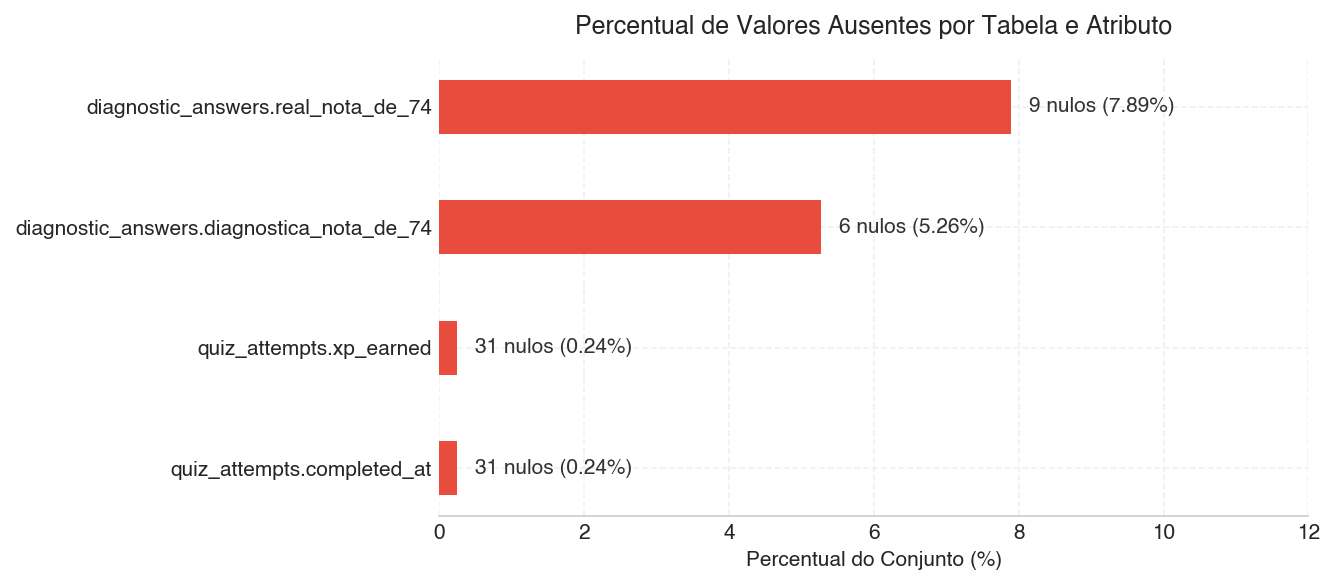

In [2]:
# Análise de Valores Ausentes em todas as tabelas
missing_data = []
for name, df in [
    ('quiz_attempts', df_quizzes),
    ('diagnostic_answers', df_diag),
    ('user_questions', df_questions),
    ('users_matched', df_users)
]:
    n_rows = len(df)
    for col, count in df.isnull().sum().items():
        if count > 0:
            missing_data.append({
                'Atributo': f"{name}.{col}",
                'Nulos': count,
                'Percentual': (count / n_rows) * 100
            })

df_miss = pd.DataFrame(missing_data).sort_values('Percentual', ascending=True)

fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
bars = ax.barh(df_miss['Atributo'], df_miss['Percentual'], color='#E74C3C', height=0.45, edgecolor='none')

for bar, (_, r) in zip(bars, df_miss.iterrows()):
    ax.text(
        bar.get_width() + 0.25, 
        bar.get_y() + bar.get_height() / 2, 
        f"{r['Nulos']} nulos ({r['Percentual']:.2f}%)", 
        va='center', 
        fontsize=10, 
        fontweight='bold', 
        color='#333333'
    )

ax.set_xlim(0, 12)
ax.set_title("Percentual de Valores Ausentes por Tabela e Atributo", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Percentual do Conjunto (%)", fontsize=10, fontweight='bold')
sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

# Anatomia da Evasão e Isolamento de N = 100
df_paired = df_diag.dropna(subset=['diagnostica_nota_de_74', 'real_nota_de_74']).copy()
df_paired['delta'] = df_paired['real_nota_de_74'] - df_paired['diagnostica_nota_de_74']

print(f"=== RESULTADO DA LIMPEZA DE DADOS (SLIDE 2) ===")
print(f"• Total de alunos cadastrados:         {len(df_diag)}")
print(f"• Alunos apenas na Prova Diagnóstica:  {(df_diag['real_nota_de_74'].isna() & df_diag['diagnostica_nota_de_74'].notna()).sum()}")
print(f"• Alunos apenas na Prova Real:         {(df_diag['diagnostica_nota_de_74'].isna() & df_diag['real_nota_de_74'].notna()).sum()}")
print(f"• Alunos ausentes em ambas as provas:  {(df_diag['diagnostica_nota_de_74'].isna() & df_diag['real_nota_de_74'].isna()).sum()}")
print(f"• AMOSTRA PAREADA FINAL (N LIMPO):     {len(df_paired)} alunos com pares completos (ZERO IMPUTAÇÃO)")


## Slide 3: Onde Estavam os Outliers? A Anomalia dos 2 Segundos

Pelo critério padrão de Tukey ($1.5 \times \text{IQR}$), a distribuição das notas não possui nenhum outlier. 
Porém, ao investigar os microdados de telemetria em `time_taken_seconds` nas 59.691 respostas, encontramos o verdadeiro problema de produto:
* **46,3% de todas as respostas** foram dadas em **$\le 2$ segundos** (com 2.021 respostas em 0 segundos cravados).
* Em $\le 2$s o acerto é de apenas **52,6%** (equivalente ao chute aleatório). Acima de 6s, salta para **quase 80%**.
* Na 1ª tentativa o tempo mediano é de 7,0s. A partir da 2ª tentativa, despenca para **2,0s cravados**, mas o acerto sobe para 68,7%, comprovando que o aluno decora a posição da alternativa correta por força bruta.


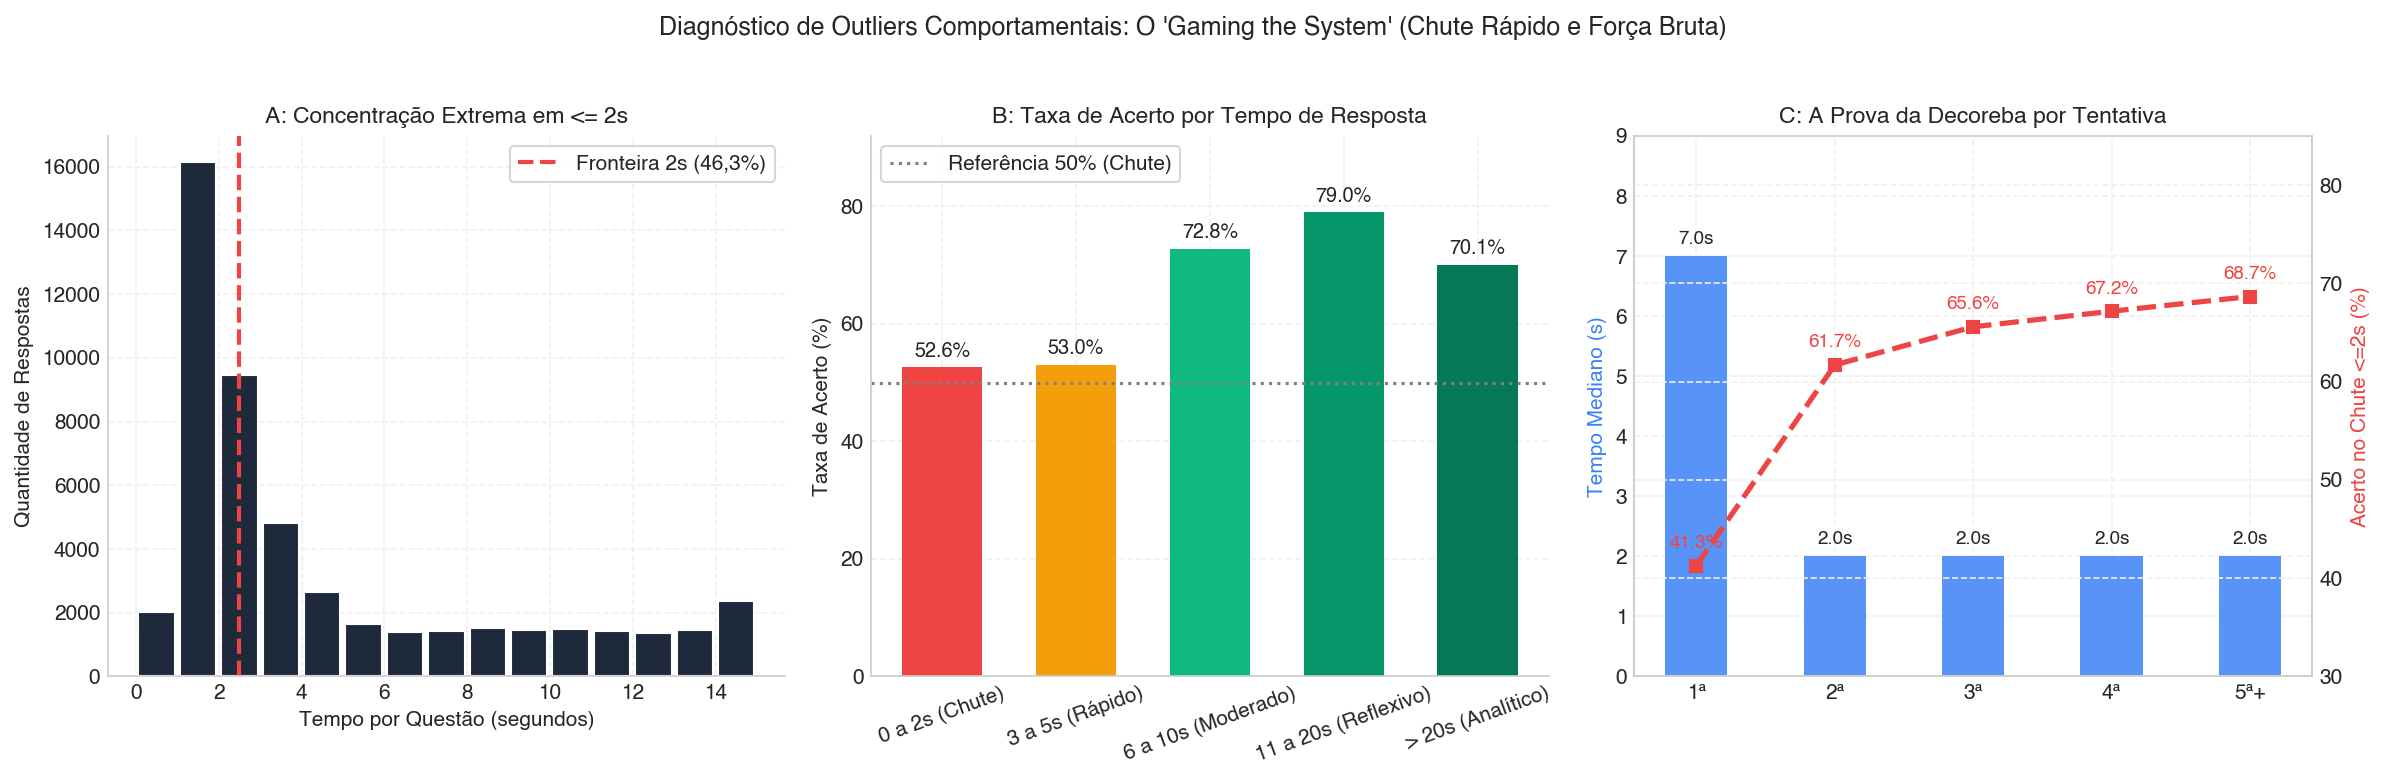

In [3]:
# Preparação dos dados de tempo e acurácia
df_questions['faixa_tempo'] = pd.cut(
    df_questions['time_taken_seconds'],
    bins=[-1, 2, 5, 10, 20, 180],
    labels=['0 a 2s (Chute)', '3 a 5s (Rápido)', '6 a 10s (Moderado)', '11 a 20s (Reflexivo)', '> 20s (Analítico)']
)
acc_time = df_questions.groupby('faixa_tempo', observed=False)['is_correct'].mean() * 100

# Cruzamento com número da tentativa
df_q_att = df_questions.merge(df_quizzes[['id', 'attempt_number']], left_on='quiz_attempt_id', right_on='id', how='left')
df_q_att['att_group'] = df_q_att['attempt_number'].apply(lambda x: f'{x}ª' if x <= 4 else '5ª+')

att_summary = df_q_att.groupby('att_group', observed=False).agg(
    med_time=('time_taken_seconds', 'median'),
    acc_geral=('is_correct', 'mean'),
    acc_sub2=('is_correct', lambda s: s[df_q_att.loc[s.index, 'time_taken_seconds'] <= 2].mean() * 100)
).reindex(['1ª', '2ª', '3ª', '4ª', '5ª+'])
att_summary['acc_geral'] = att_summary['acc_geral'] * 100

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5), dpi=150)

# Painel A: Histograma <= 15s
ax1.hist(df_questions['time_taken_seconds'], bins=range(0, 16), color='#1E293B', edgecolor='white', rwidth=0.88)
ax1.axvline(2.5, color='#EF4444', linestyle='--', linewidth=2, label='Fronteira 2s (46,3%)')
ax1.set_title("A: Concentração Extrema em <= 2s", fontsize=11, fontweight='bold')
ax1.set_xlabel("Tempo por Questão (segundos)", fontsize=10, fontweight='bold')
ax1.set_ylabel("Quantidade de Respostas", fontsize=10, fontweight='bold')
ax1.legend(frameon=True, facecolor='white', loc='upper right')
sns.despine(ax=ax1)

# Painel B: Acurácia vs Tempo
colors_acc = ['#EF4444', '#F59E0B', '#10B981', '#059669', '#047857']
bars_b = ax2.bar(acc_time.index, acc_time.values, color=colors_acc, width=0.6)
ax2.axhline(50, color='gray', linestyle=':', label='Referência 50% (Chute)')
for bar in bars_b:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 1.8, f"{yval:.1f}%", ha='center', fontsize=9.5, fontweight='bold')
ax2.set_ylim(0, 92)
ax2.set_title("B: Taxa de Acerto por Tempo de Resposta", fontsize=11, fontweight='bold')
ax2.set_ylabel("Taxa de Acerto (%)", fontsize=10, fontweight='bold')
ax2.tick_params(axis='x', rotation=20)
ax2.legend(frameon=True, facecolor='white', loc='upper left')
sns.despine(ax=ax2)

# Painel C: Efeito Decoreba por Tentativa
ax3_twin = ax3.twinx()
bars_c = ax3.bar(att_summary.index, att_summary['med_time'], color='#3B82F6', width=0.45, label='Tempo Mediano (s)', alpha=0.85)
line_c = ax3_twin.plot(att_summary.index, att_summary['acc_sub2'], color='#EF4444', marker='s', linewidth=2.5, linestyle='--', label='Acerto em <= 2s (%)')

for bar in bars_c:
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, f"{bar.get_height():.1f}s", ha='center', fontsize=9, fontweight='bold')
for i, yval in enumerate(att_summary['acc_sub2']):
    ax3_twin.text(i, yval + 1.8, f"{yval:.1f}%", ha='center', fontsize=9, fontweight='bold', color='#EF4444')

ax3.set_ylim(0, 9)
ax3_twin.set_ylim(30, 85)
ax3.set_title("C: A Prova da Decoreba por Tentativa", fontsize=11, fontweight='bold')
ax3.set_ylabel("Tempo Mediano (s)", fontsize=10, fontweight='bold', color='#3B82F6')
ax3_twin.set_ylabel("Acerto no Chute <=2s (%)", fontsize=10, fontweight='bold', color='#EF4444')
sns.despine(ax=ax3, right=False)

plt.suptitle("Diagnóstico de Outliers Comportamentais: O 'Gaming the System' (Chute Rápido e Força Bruta)", fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## Slide 4: A Nota Subiu, mas a Causa Não Foi o App

A nota média geral subiu de 44,6 para 48,5 (+3,88 pontos, teste $t$ pareado $p < 0,001$). Uma equipe ingênua afirmaria que o aplicativo foi o causador desse ganho.

No entanto, a análise econométrica detalhada desmascara essa hipótese:
1. **Regressão à Média de Galton ($R = -0,560, p < 0,0001$):** Quem tirou notas baixas no pré subiu $+10,2$ pontos (convergiu para a média); quem tirou notas altas caiu $-6,0$ pontos.
2. **Causalidade Nula:** Em modelo OLS controlando pela nota inicial, o volume de questões respondidas tem coeficiente nulo ($p = 0,28$).
3. **Disparidade por Série:** O ganho foi liderado pelo 3º Ano (+6,9 pts), enquanto o 2º Ano estagnou completamente (+0,9 pt).


Coeficiente de Correlação de Galton (Nota Pré vs Delta): R = -0.5605 (p = 1.3305e-09)



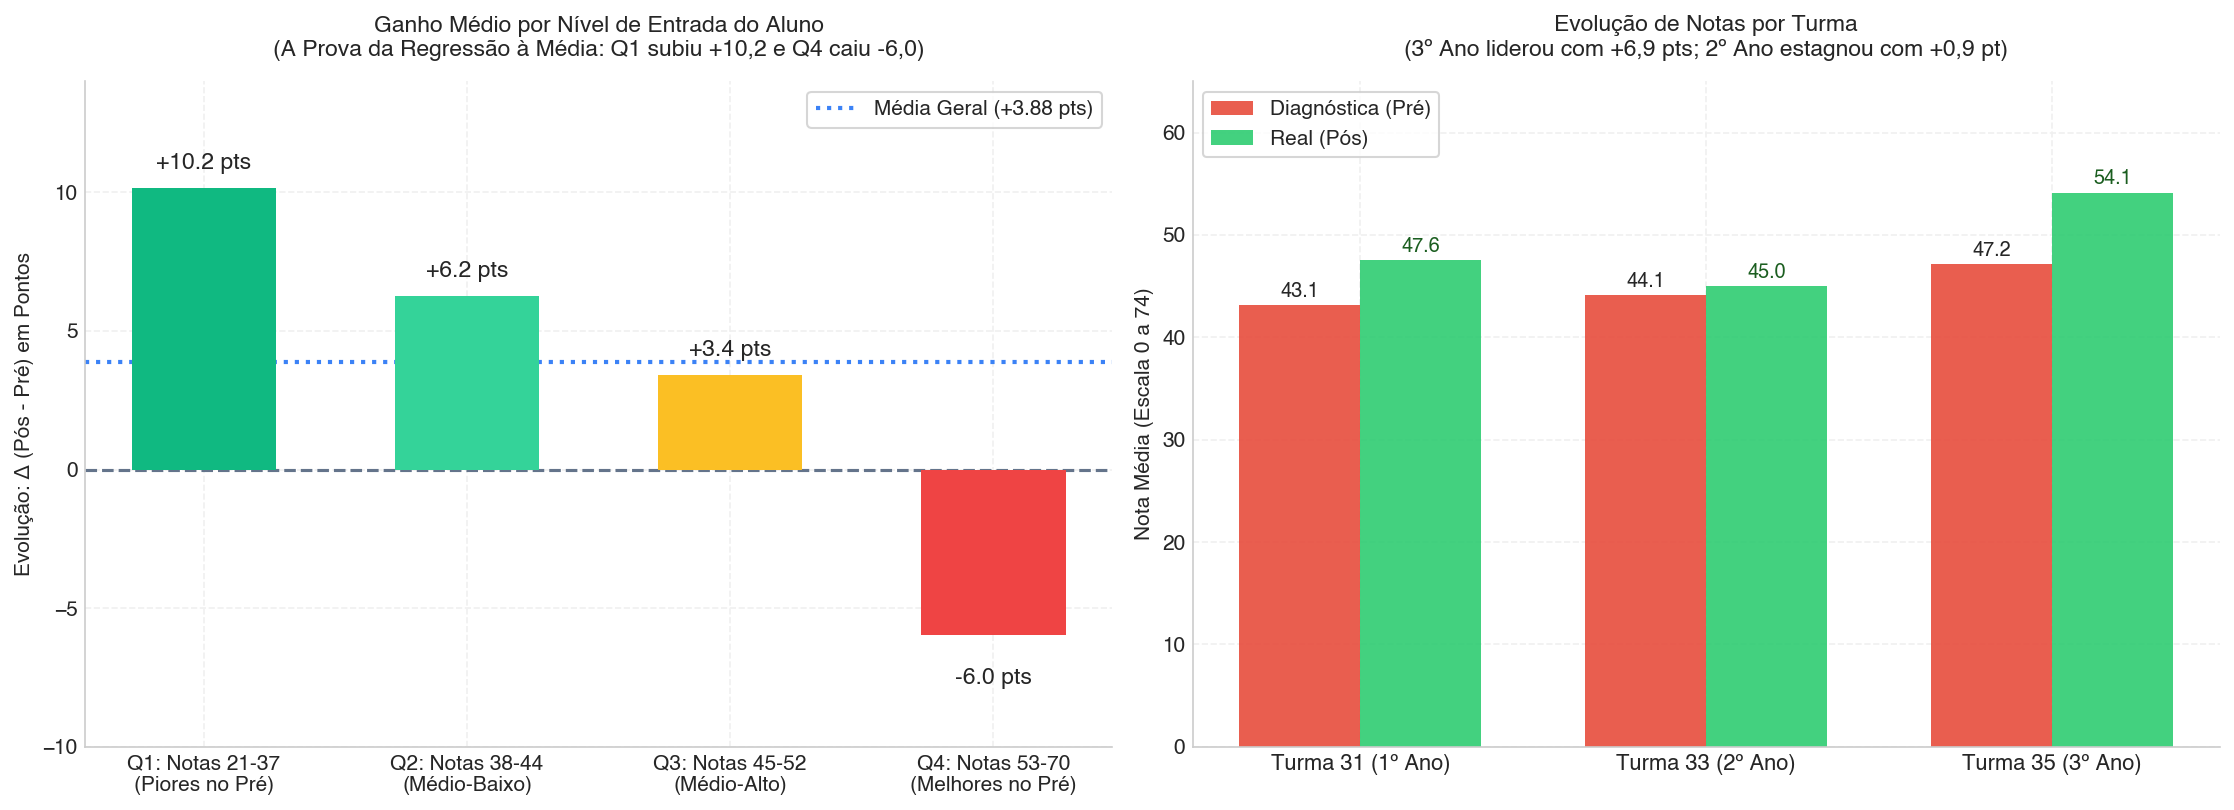

In [4]:
# 1. Agrupamento em Quartis do Pré-Teste
df_paired['quartil_pre'] = pd.qcut(
    df_paired['diagnostica_nota_de_74'], 
    q=4, 
    labels=[
        'Q1: Notas 21-37\n(Piores no Pré)', 
        'Q2: Notas 38-44\n(Médio-Baixo)', 
        'Q3: Notas 45-52\n(Médio-Alto)', 
        'Q4: Notas 53-70\n(Melhores no Pré)'
    ]
)
q_agg = df_paired.groupby('quartil_pre', observed=False)['delta'].mean().reset_index()

# 2. Médias por Turma
df_turmas = df_paired.groupby('turma').agg(
    pre_media=('diagnostica_nota_de_74', 'mean'),
    pos_media=('real_nota_de_74', 'mean'),
    delta_media=('delta', 'mean')
).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=150)

# Gráfico 1: Ganho por Quartil
cores_barras = ['#10B981', '#34D399', '#FBBF24', '#EF4444']
bars1 = ax1.bar(q_agg['quartil_pre'], q_agg['delta'], color=cores_barras, width=0.55, edgecolor='none', zorder=3)
ax1.axhline(0, color='#64748B', linestyle='--', linewidth=1.5)

for bar in bars1:
    yval = bar.get_height()
    va = 'bottom' if yval >= 0 else 'top'
    offset = 0.5 if yval >= 0 else -1.2
    sinal = '+' if yval > 0 else ''
    ax1.text(bar.get_x() + bar.get_width()/2, yval + offset, f'{sinal}{yval:.1f} pts', ha='center', va=va, fontsize=11, fontweight='bold')

ax1.axhline(3.88, color='#3B82F6', linestyle=':', linewidth=2, label='Média Geral (+3.88 pts)')
ax1.set_title("Ganho Médio por Nível de Entrada do Aluno\n(A Prova da Regressão à Média: Q1 subiu +10,2 e Q4 caiu -6,0)", fontsize=11, fontweight='bold', pad=12)
ax1.set_ylabel("Evolução: Δ (Pós - Pré) em Pontos", fontsize=10, fontweight='bold')
ax1.set_ylim(-10, 14)
ax1.legend(frameon=True, facecolor='white', loc='upper right')
sns.despine(ax=ax1)

# Gráfico 2: Evolução por Turma
turma_labels = ['Turma 31 (1º Ano)', 'Turma 33 (2º Ano)', 'Turma 35 (3º Ano)']
x = np.arange(len(turma_labels))
width = 0.35

bars2_pre = ax2.bar(x - width/2, df_turmas['pre_media'], width, label='Diagnóstica (Pré)', color='#E74C3C', alpha=0.9)
bars2_pos = ax2.bar(x + width/2, df_turmas['pos_media'], width, label='Real (Pós)', color='#2ECC71', alpha=0.9)

for bar in bars2_pre:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8, f"{bar.get_height():.1f}", ha='center', fontsize=9.5)
for bar in bars2_pos:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8, f"{bar.get_height():.1f}", ha='center', fontsize=9.5, fontweight='bold', color='#1B5E20')

ax2.set_xticks(x)
ax2.set_xticklabels(turma_labels, fontsize=10.5, fontweight='bold')
ax2.set_ylabel("Nota Média (Escala 0 a 74)", fontsize=10, fontweight='bold')
ax2.set_ylim(0, 65)
ax2.set_title("Evolução de Notas por Turma\n(3º Ano liderou com +6,9 pts; 2º Ano estagnou com +0,9 pt)", fontsize=11, fontweight='bold', pad=12)
ax2.legend(frameon=True, facecolor='white', loc='upper left')
sns.despine(ax=ax2)

plt.tight_layout()
plt.show()

# Correlação de Galton
r_galton, p_galton = stats.pearsonr(df_paired['diagnostica_nota_de_74'], df_paired['delta'])
print(f"Coeficiente de Correlação de Galton (Nota Pré vs Delta): R = {r_galton:.4f} (p = {p_galton:.4e})")


## Slide 5: Os Problemas Estruturais e as Soluções Desenhadas

Investigando os metadados temporais e a estrutura pedagógica do aplicativo, identificamos duas causas raízes estruturais:
1. **A "Temporalidade Reversa":** A prova presencial ocorreu no dia 04/09, mas **85% de todas as tentativas (10.799)** aconteceram DEPOIS da prova, motivadas pelo encerramento do prazo escolar para lançamento de nota bimestral em 10/09.
2. **Gargalo e Assimetria de Catálogo:** Os módulos temáticos das aulas presenciais (69, 70 e 71) tinham apenas 8 quizzes cada. Os alunos esgotaram o conteúdo em 2 dias e ficaram confinados ao Módulo 68 (Reforço geral, com 80 quizzes), onde ocorreram 70,9% das tentativas.


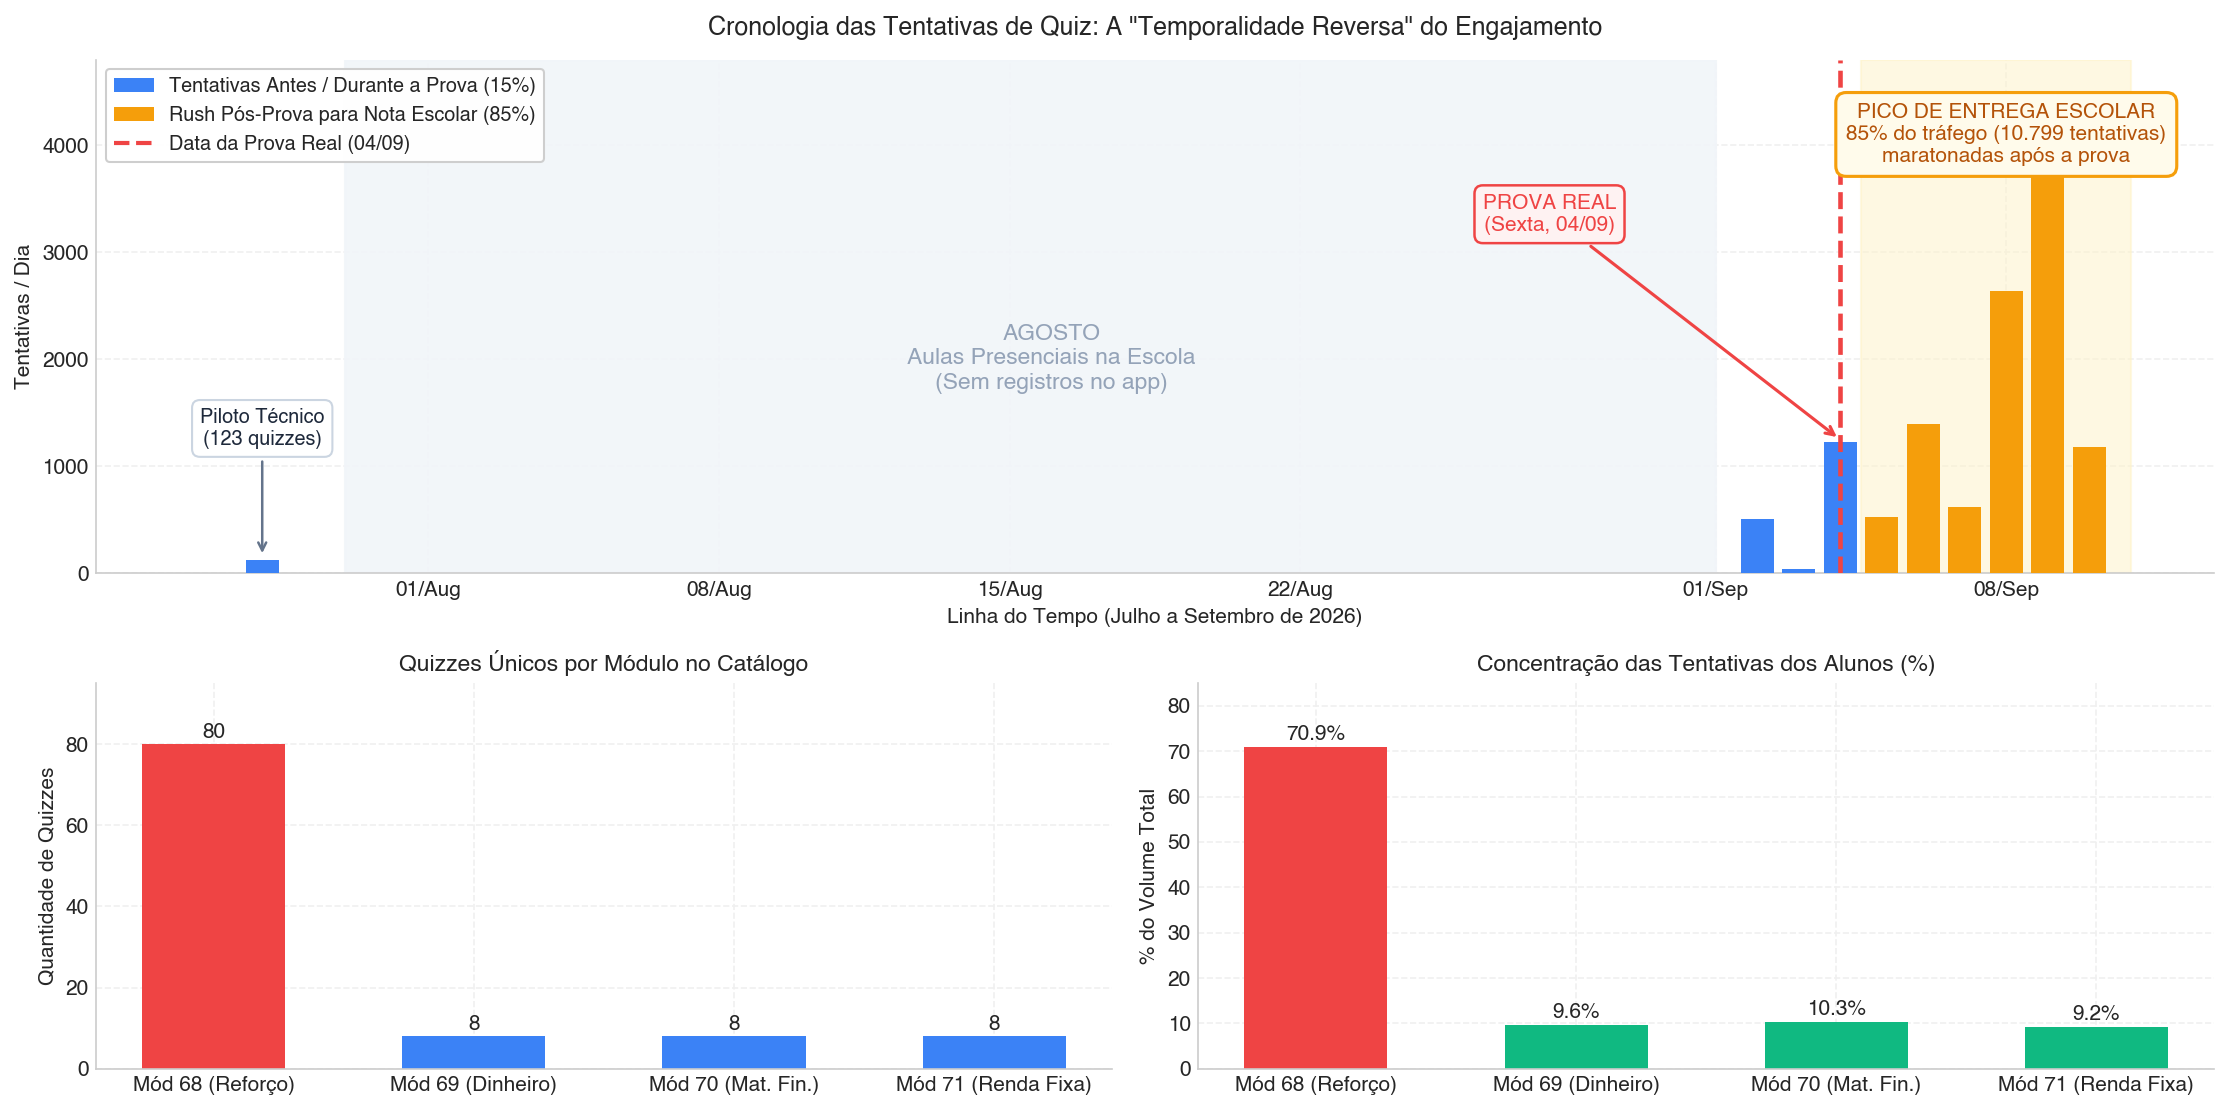

In [5]:
# Preparação da Linha do Tempo e Módulos
df_quizzes['dia'] = pd.to_datetime(df_quizzes['started_at']).dt.date
daily = df_quizzes.groupby('dia').size().reset_index(name='tentativas')
daily['dia'] = pd.to_datetime(daily['dia'])

module_agg = df_quizzes.groupby('module_id').agg(
    total_tentativas=('id', 'count'),
    quizzes_unicos=('quiz_id', 'nunique')
).reset_index()
module_agg['pct_tentativas'] = (module_agg['total_tentativas'] / df_quizzes.shape[0]) * 100
mod_labels = ['Mód 68 (Reforço)', 'Mód 69 (Dinheiro)', 'Mód 70 (Mat. Fin.)', 'Mód 71 (Renda Fixa)']

fig = plt.figure(figsize=(15, 7.5), dpi=150)
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 0.9])

ax_top = fig.add_subplot(gs[0, :])
ax_b1 = fig.add_subplot(gs[1, 0])
ax_b2 = fig.add_subplot(gs[1, 1])

# Top: Linha do Tempo Ultra-Legível
cores_dia = ['#3B82F6' if d <= pd.to_datetime('2026-09-04') else '#F59E0B' for d in daily['dia']]
ax_top.bar(daily['dia'], daily['tentativas'], width=0.8, color=cores_dia, edgecolor='none', zorder=3)
ax_top.axvline(pd.to_datetime('2026-09-04'), color='#EF4444', linestyle='--', linewidth=2.2, zorder=4)

# Faixa de Agosto
ax_top.axvspan(pd.to_datetime('2026-07-30'), pd.to_datetime('2026-09-01'), color='#F1F5F9', alpha=0.9, zorder=1)
ax_top.text(pd.to_datetime('2026-08-16'), 2000, 'AGOSTO\nAulas Presenciais na Escola\n(Sem registros no app)', ha='center', va='center', fontsize=11, fontweight='bold', color='#94A3B8', zorder=2)
ax_top.axvspan(pd.to_datetime('2026-09-04 12:00:00'), pd.to_datetime('2026-09-10 23:59:59'), color='#FEF3C7', alpha=0.5, zorder=1)

# Anotações
ax_top.annotate('Piloto Técnico\n(123 quizzes)', xy=(pd.to_datetime('2026-07-28'), 150), xytext=(pd.to_datetime('2026-07-28'), 1200),
                ha='center', fontsize=9.5, fontweight='bold', color='#1E293B',
                arrowprops=dict(arrowstyle='->', color='#64748B', lw=1.2),
                bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#CBD5E1', lw=1), zorder=5)

ax_top.annotate('PROVA REAL\n(Sexta, 04/09)', xy=(pd.to_datetime('2026-09-04'), 1250), xytext=(pd.to_datetime('2026-08-28'), 3200),
                ha='center', fontsize=10, fontweight='bold', color='#EF4444',
                arrowprops=dict(arrowstyle='->', color='#EF4444', lw=1.5),
                bbox=dict(boxstyle='round,pad=0.4', facecolor='#FEF2F2', edgecolor='#EF4444', lw=1.2), zorder=5)

ax_top.text(pd.to_datetime('2026-09-08'), 4100, 'PICO DE ENTREGA ESCOLAR\n85% do tráfego (10.799 tentativas)\nmaratonadas após a prova',
            ha='center', va='center', fontsize=10, fontweight='bold', color='#B45309',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#FFFBEB', edgecolor='#F59E0B', lw=1.5), zorder=5)

ax_top.xaxis.set_major_formatter(mdates.DateFormatter('%d/%b'))
ax_top.set_xlim(pd.to_datetime('2026-07-24'), pd.to_datetime('2026-09-13'))
ax_top.set_ylim(0, 4800)
ax_top.set_title('Cronologia das Tentativas de Quiz: A "Temporalidade Reversa" do Engajamento', fontsize=12, fontweight='bold', pad=12)
ax_top.set_ylabel('Tentativas / Dia', fontsize=10, fontweight='bold')
ax_top.set_xlabel('Linha do Tempo (Julho a Setembro de 2026)', fontsize=10, fontweight='bold')

legend_el = [
    Patch(facecolor='#3B82F6', label='Tentativas Antes / Durante a Prova (15%)'),
    Patch(facecolor='#F59E0B', label='Rush Pós-Prova para Nota Escolar (85%)'),
    Line2D([0], [0], color='#EF4444', lw=2, linestyle='--', label='Data da Prova Real (04/09)')
]
ax_top.legend(handles=legend_el, frameon=True, facecolor='white', framealpha=0.95, loc='upper left', fontsize=9.5)
sns.despine(ax=ax_top)

# Bottom 1: Catálogo
bars_b1 = ax_b1.bar(mod_labels, module_agg['quizzes_unicos'], color=['#EF4444', '#3B82F6', '#3B82F6', '#3B82F6'], width=0.55)
for bar in bars_b1:
    ax_b1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f"{int(bar.get_height())}", ha='center', fontsize=10, fontweight='bold')
ax_b1.set_ylim(0, 95)
ax_b1.set_title("Quizzes Únicos por Módulo no Catálogo", fontsize=11, fontweight='bold')
ax_b1.set_ylabel("Quantidade de Quizzes", fontsize=10, fontweight='bold')
sns.despine(ax=ax_b1)

# Bottom 2: % Tentativas
bars_b2 = ax_b2.bar(mod_labels, module_agg['pct_tentativas'], color=['#EF4444', '#10B981', '#10B981', '#10B981'], width=0.55)
for bar in bars_b2:
    ax_b2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f"{bar.get_height():.1f}%", ha='center', fontsize=10, fontweight='bold')
ax_b2.set_ylim(0, 85)
ax_b2.set_title("Concentração das Tentativas dos Alunos (%)", fontsize=11, fontweight='bold')
ax_b2.set_ylabel("% do Volume Total", fontsize=10, fontweight='bold')
sns.despine(ax=ax_b2)

plt.tight_layout()
plt.show()


In [6]:
# Teste Econométrico OLS: Avaliando o Impacto Causal do App na Nota
DATA_PROVA = pd.to_datetime('2026-09-04 23:59:59')
quizzes_pre_test = df_quizzes[df_quizzes['started_at'] <= DATA_PROVA].groupby('user_id').size().rename('quizzes_antes_prova')

df_model = df_paired.merge(quizzes_pre_test, left_on='matched_user_id', right_on='user_id', how='left')
df_model['quizzes_antes_prova'] = df_model['quizzes_antes_prova'].fillna(0)
df_model['usou_antes'] = df_model['quizzes_antes_prova'] > 0

mean_user = df_model[df_model['usou_antes']]['delta'].mean()
mean_non = df_model[~df_model['usou_antes']]['delta'].mean()

print(f"=== COMPARAÇÃO DO GANHO MÉDIO (Δ) ANTES DA PROVA ===")
print(f"• Alunos que USARAM o app antes da prova (N = {df_model['usou_antes'].sum()}):     +{mean_user:.2f} pontos")
print(f"• Alunos que NÃO USARAM o app antes da prova (N = {(~df_model['usou_antes']).sum()}): +{mean_non:.2f} pontos")

# Regressão Múltipla OLS: Delta ~ Nota Pré + Quizzes Antes da Prova
X = sm.add_constant(df_model[['diagnostica_nota_de_74', 'quizzes_antes_prova']])
y = df_model['delta']
ols = sm.OLS(y, X).fit()

print("\n=== RESULTADO DA REGRESSÃO MULTIVARIADA OLS ===")
print(ols.summary().tables[1])


=== COMPARAÇÃO DO GANHO MÉDIO (Δ) ANTES DA PROVA ===
• Alunos que USARAM o app antes da prova (N = 60):     +2.58 pontos
• Alunos que NÃO USARAM o app antes da prova (N = 40): +5.83 pontos

=== RESULTADO DA REGRESSÃO MULTIVARIADA OLS ===
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     29.4407      3.900      7.549      0.000      21.700      37.181
diagnostica_nota_de_74    -0.5622      0.084     -6.702      0.000      -0.729      -0.396
quizzes_antes_prova       -0.0269      0.033     -0.819      0.415      -0.092       0.038



## Slides 6 e 7: A Proposta de Produto — Engenharia Anti-Chute & A Nova SIA Arena

Para transformar a alta tração da SIA em aprendizagem efetiva e nota na OLITEF, desenhamos uma solução com 3 pilares de engenharia e uma experiência de jogo envolvente:

### 1. IA & Questões Paramétricas (Cura a Decoreba e o Catálogo Raso)
* **Valores Dinâmicos por IA:** Enunciados gerados via RAG sobre a matriz da OLITEF com taxas, prazos e capitais que mudam a cada tentativa. O conceito é o mesmo, mas o número muda: decorar a letra anterior deixa de funcionar.
* **Catálogo Infinito:** Expansão automática dos módulos temáticos para que o aluno nunca esgote o conteúdo.

### 2. Fricção Cognitiva Anti-Chute (Cura os 46,3% em $\le 2$s)
* **Trava Inteligente de Leitura:** Bloqueio de submissão nos primeiros 3 a 4 segundos proporcional ao tamanho do texto.
* **Janela Ótima de Aprendizado:** Indução ativa para respostas na faixa entre 6s e 20s, onde os dados provam que o acerto atinge quase **80%**.

### 3. A Nova Experiência: SIA Arena & Mascote na Solana
* **Arena 1v1:** Duelos rápidos entre alunos treinando questões reais de prova ao longo das semanas de aula (eliminando o apagão de agosto).
* **Batalha contra a Falência (Boss Fight):** O aluno conclui o módulo enfrentando o Monstro da Falência com 3 corações/vidas.
* **Recompensa em cNFTs na Solana:** Vencer a batalha desbloqueia armaduras, escudos e skins para personalizar o Porquinho, cunhados on-chain na Solana (via Superteam) a custo de centavos para a escola.


In [7]:
# Geração da Matriz de Validação (Slide 8)
table_data = [
    ['KPI de Validação', 'Baseline Atual (Dados SIA)', 'Meta Esperada (Pós-Arena)', 'Impacto Pedagógico / Negócio'],
    ['1. Respostas em ≤ 2s (Chute)', '46,3% (27.636 respostas)', '< 10%', 'Fim do comportamento arcade e chute cego'],
    ['2. Tempo Mediano na 2ª+ Tentativa', '2,0 segundos cravados', '> 6,0 segundos', 'Fim da força bruta e da decoreba rápida'],
    ['3. Tentativas Médias até Conclusão', '5+ tentativas em looping', '1 a 2 tentativas analíticas', 'Leitura e aprendizado conceitual efetivo'],
    ['4. Temporalidade das Tentativas', '15% pré-prova / 85% pós-prova', '> 70% pré-prova (semanas de aula)', 'Estudo ativo para a prova, não rush burocrático'],
    ['5. Impacto Causal na Nota Real', 'p = 0,415 (efeito nulo)', 'p < 0,05 (efeito causal positivo)', 'SIA comprova cientificamente o ganho de nota']
]

df_kpis = pd.DataFrame(table_data[1:], columns=table_data[0])
print("=== MATRIZ DE KPIS DO PLANO DE VALIDAÇÃO (SLIDE 8) ===")
print(df_kpis.to_string(index=False))

print("\n=== RECOMENDAÇÕES TÉCNICAS DE SCHEMA PARA A SIA ===")
print("1. Adicionar question_id na tabela user_question_answers (identificar falhas em itens individuais)")
print("2. Telemetria Server-Side para time_taken_seconds (validação contra adulteração de relógio)")
print("3. Desenho Experimental A/B entre turmas para medição de ganho causal limpo (p < 0,05)")


=== MATRIZ DE KPIS DO PLANO DE VALIDAÇÃO (SLIDE 8) ===
                  KPI de Validação    Baseline Atual (Dados SIA)         Meta Esperada (Pós-Arena)                    Impacto Pedagógico / Negócio
      1. Respostas em ≤ 2s (Chute)      46,3% (27.636 respostas)                             < 10%        Fim do comportamento arcade e chute cego
 2. Tempo Mediano na 2ª+ Tentativa         2,0 segundos cravados                    > 6,0 segundos         Fim da força bruta e da decoreba rápida
3. Tentativas Médias até Conclusão      5+ tentativas em looping       1 a 2 tentativas analíticas        Leitura e aprendizado conceitual efetivo
   4. Temporalidade das Tentativas 15% pré-prova / 85% pós-prova > 70% pré-prova (semanas de aula) Estudo ativo para a prova, não rush burocrático
    5. Impacto Causal na Nota Real       p = 0,415 (efeito nulo) p < 0,05 (efeito causal positivo)    SIA comprova cientificamente o ganho de nota

=== RECOMENDAÇÕES TÉCNICAS DE SCHEMA PARA A SIA ===
1. Adicion

## Gabarito Oficial: Respostas às 7 Perguntas do Edital (Pág. 10)

1. **Problema nas Respostas:** 46,3% das respostas em $\le 2$s com taxa de acerto de 52,6% (chute). Queda para 2,0s cravados na 2ª tentativa (força bruta).
2. **Disponibilidade de Perguntas:** Catálogo assimétrico com apenas 8 quizzes por módulo curricular contra 80 no módulo de reforço, provocando esgotamento em 2 dias.
3. **Incentivo do Aluno:** Motivação burocrática por nota escolar bimestral com prazo em 10/09, gerando 85% do uso concentrado após a prova real.
4. **Melhoria Frente ao Intensivão:** Ganho médio de +3,88 pontos dominado por Regressão à Média ($R = -0,560$): o quartil mais baixo subiu $+10,2$ e o mais alto caiu $-6,0$.
5. **Influência do Número de Questões na Nota:** Causalidade estatisticamente nula ($p = 0,279$). Mais cliques não geraram maior nota.
6. **É Possível Afirmar Aumento do Aprendizado Só com o App?** Não. A ausência de grupo de controle e a temporalidade reversa tornam cientificamente impossível isolar o efeito do app.
7. **O que Faltou Metrificar?** Falta do `question_id` na tabela de respostas, telemetria de tempo no servidor e presença física nas aulas.
